In [5]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Everything is working!")

Everything is working!


In [7]:
# Load the dataset

df = pd.read_csv("StudentPerformanceFactors.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [8]:
# Display the first 5 rows

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [9]:
# Display the last 5 rows

df.tail()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
6602,25,69,High,Medium,No,7,76,Medium,Yes,1,High,Medium,Public,Positive,2,No,High School,Near,Female,68
6603,23,76,High,Medium,No,8,81,Medium,Yes,3,Low,High,Public,Positive,2,No,High School,Near,Female,69
6604,20,90,Medium,Low,Yes,6,65,Low,Yes,3,Low,Medium,Public,Negative,2,No,Postgraduate,Near,Female,68
6605,10,86,High,High,Yes,6,91,High,Yes,2,Low,Medium,Private,Positive,3,No,High School,Far,Female,68
6606,15,67,Medium,Low,Yes,9,94,Medium,Yes,0,Medium,Medium,Public,Positive,4,No,Postgraduate,Near,Male,64


In [10]:
# Check the number of rows and columns

print("Rows and columns:", df.shape)

Rows and columns: (6607, 20)


In [11]:
# Display column names

print("Column names:")
print(df.columns.tolist())

Column names:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [12]:
# Check data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [13]:
# Basic statistical summary

df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [14]:
# Number of unique values in each column

df.nunique()

Hours_Studied                 41
Attendance                    41
Parental_Involvement           3
Access_to_Resources            3
Extracurricular_Activities     2
Sleep_Hours                    7
Previous_Scores               51
Motivation_Level               3
Internet_Access                2
Tutoring_Sessions              9
Family_Income                  3
Teacher_Quality                3
School_Type                    2
Peer_Influence                 3
Physical_Activity              7
Learning_Disabilities          2
Parental_Education_Level       3
Distance_from_Home             3
Gender                         2
Exam_Score                    45
dtype: int64

### Initial Observations

- The dataset contains **6,607 observations and 20 columns**.
- The target variable, Exam_Score, represents the exam score to be predicted.
- The dataset includes academic, study-related, and lifestyle factors such as study hours, attendance, previous scores, sleep hours, and tutoring sessions.
- These factors may help explain variations in student exam performance and can be used to train a regression model.

In [15]:
# Check for missing values

df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [35]:
# Handle missing values in all columns

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after handling:")
print(df.isnull().sum())

Missing values after handling:
Hours_Studied                 0
Attendance                    0
Parental_Involvement          0
Access_to_Resources           0
Extracurricular_Activities    0
Sleep_Hours                   0
Previous_Scores               0
Motivation_Level              0
Internet_Access               0
Tutoring_Sessions             0
Family_Income                 0
Teacher_Quality               0
School_Type                   0
Peer_Influence                0
Physical_Activity             0
Learning_Disabilities         0
Parental_Education_Level      0
Distance_from_Home            0
Gender                        0
Exam_Score                    0
dtype: int64


In [16]:
# Check for duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [18]:
# Check for invalid values in numerical columns

print("Study hours below 0:", (df["Hours_Studied"] < 0).sum())
print("Attendance outside 0-100:", ((df["Attendance"] < 0) | (df["Attendance"] > 100)).sum())
print("Sleep hours outside 0-24:", ((df["Sleep_Hours"] < 0) | (df["Sleep_Hours"] > 24)).sum())
print("Previous scores outside 0-100:", ((df["Previous_Scores"] < 0) | (df["Previous_Scores"] > 100)).sum())
print("Exam scores outside 0-100:", ((df["Exam_Score"] < 0) | (df["Exam_Score"] > 100)).sum())

Study hours below 0: 0
Attendance outside 0-100: 0
Sleep hours outside 0-24: 0
Previous scores outside 0-100: 0
Exam scores outside 0-100: 1


In [19]:
# Inspect exam scores outside the 0-100 range
df.loc[
    (df["Exam_Score"] < 0) | (df["Exam_Score"] > 100),
    ["Exam_Score", "Hours_Studied", "Attendance", "Previous_Scores"]
]

,Exam_Score,Hours_Studied,Attendance,Previous_Scores
1525,101,27,98,93


In [20]:
# Remove rows with invalid exam scores
df = df[(df["Exam_Score"] >= 0) & (df["Exam_Score"] <= 100)]

print("Dataset shape after removing invalid scores:", df.shape)

Dataset shape after removing invalid scores: (6606, 20)


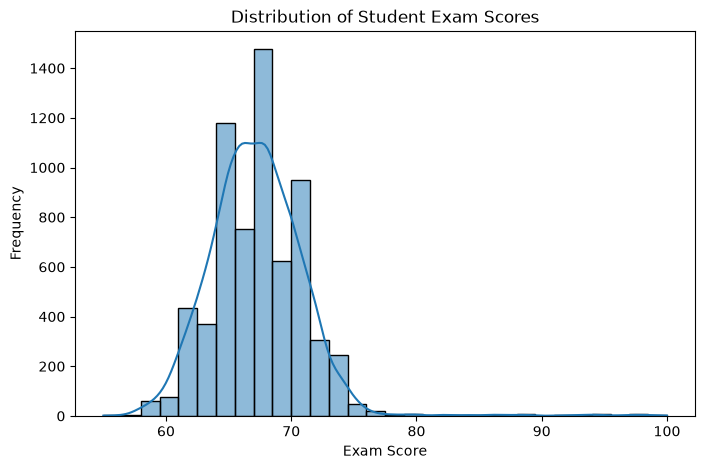

In [ ]:
# Distribution of Exam Scores
plt.figure(figsize=(8, 5))

sns.histplot(df["Exam_Score"], bins=30, kde=True)

plt.title("Distribution of Student Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")

plt.show()

**Observation:** The distribution of exam scores is concentrated mainly in the mid-to-high 60s, with fewer students achieving scores above 80. A small number of students achieve exceptionally high scores, extending the distribution towards 100.

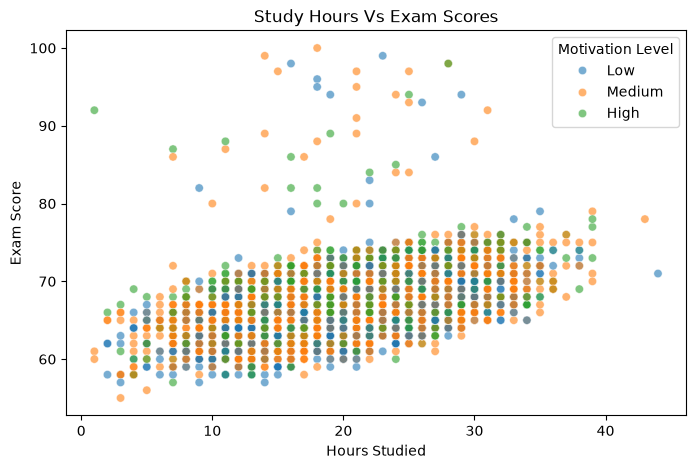

In [29]:
# Relationship between study hours and exam scores

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Hours_Studied", y="Exam_Score", hue="Motivation_Level", alpha=0.6)

plt.title("Study Hours Vs Exam Scores")
plt.xlabel("Hours Studied")
plt.ylabel("Exam Score")
plt.legend(title="Motivation Level")

plt.show()

**Observation:** Exam scores generally show an upward trend as study hours increase. However, considerable variation exists among students with similar study hours. The different motivation levels overlap substantially, suggesting that study hours alone may not fully explain differences in academic performance.


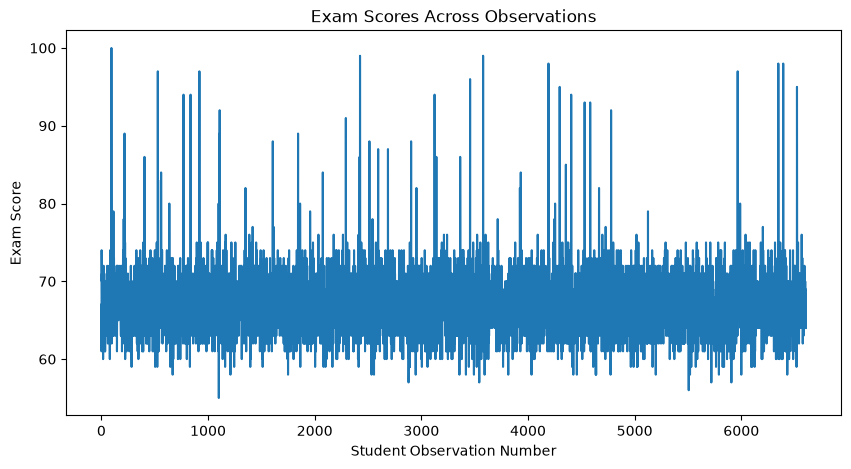

In [30]:
# Bike rental count across the dataset

plt.figure(figsize=(10, 5))
plt.plot(df["Exam_Score"])

plt.title("Exam Scores Across Observations")
plt.xlabel("Student Observation Number")
plt.ylabel("Exam Score")

plt.show()

**Observation:** Exam scores vary across the dataset, with most students scoring between approximately 60 and 75. A small number of students achieve scores above 80, with some reaching close to 100. The scores fluctuate across observations without a clear sequential trend.

In [31]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()


C:\Users\nayan\AppData\Local\Temp\ipykernel_28536\1992369538.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


In [32]:
# Define features (X) and target (y)

features = [
    "Hours_Studied",
    "Attendance",
    "Parental_Involvement",
    "Access_to_Resources",
    "Extracurricular_Activities",
    "Sleep_Hours",
    "Previous_Scores",
    "Motivation_Level",
    "Internet_Access",
    "Tutoring_Sessions",
    "Family_Income",
    "Teacher_Quality",
    "School_Type",
    "Peer_Influence",
    "Physical_Activity",
    "Learning_Disabilities",
    "Parental_Education_Level",
    "Distance_from_Home",
    "Gender"
]

X = df[features]
y = df["Exam_Score"]

print("Features:", X.columns.tolist())

Features: ['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']


In [33]:
# One-hot encode categorical variables

X = pd.get_dummies(
    X,
    columns=categorical_cols,
    dtype=int
)

print("Features after encoding:")
print(X.columns.tolist())
print("\nNew X shape:", X.shape)

Features after encoding:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity', 'Parental_Involvement_High', 'Parental_Involvement_Low', 'Parental_Involvement_Medium', 'Access_to_Resources_High', 'Access_to_Resources_Low', 'Access_to_Resources_Medium', 'Extracurricular_Activities_No', 'Extracurricular_Activities_Yes', 'Motivation_Level_High', 'Motivation_Level_Low', 'Motivation_Level_Medium', 'Internet_Access_No', 'Internet_Access_Yes', 'Family_Income_High', 'Family_Income_Low', 'Family_Income_Medium', 'Teacher_Quality_High', 'Teacher_Quality_Low', 'Teacher_Quality_Medium', 'School_Type_Private', 'School_Type_Public', 'Peer_Influence_Negative', 'Peer_Influence_Neutral', 'Peer_Influence_Positive', 'Learning_Disabilities_No', 'Learning_Disabilities_Yes', 'Parental_Education_Level_College', 'Parental_Education_Level_High School', 'Parental_Education_Level_Postgraduate', 'Distance_from_Home_Far', 'Distance_from_Home_Moderate', 'Distance_

In [37]:
# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5284, 40)
Testing features: (1322, 40)
Training target: (5284,)
Testing target: (1322,)


In [38]:
# Scale features for KNN

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

Scaled training data shape: (5284, 40)
Scaled testing data shape: (1322, 40)


## 5. Core Machine Learning Models

### 5.1 Linear Regression

In [ ]:
# Train a Linear Regression model

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Make predictions
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [ ]:
# Evaluate Linear Regression

mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("MAE:", mae_linear)
print("MSE:", mse_linear)
print("R²:", r2_linear)

Linear Regression Results
MAE: 105.13764163664806
MSE: 19784.29515511788
R²: 0.40060188452467327


Observation: Linear Regression achieved an MAE of 105.14 and an R² score of 0.401, indicating that the model provides a moderate prediction of bike rental demand but leaves considerable variation unexplained.

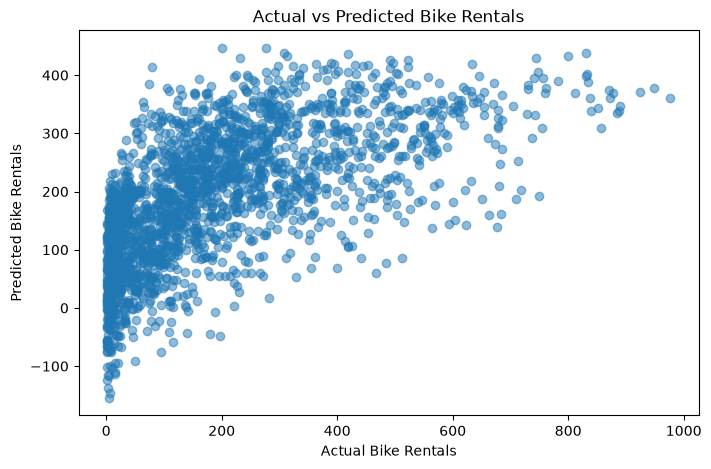

In [ ]:
# Actual vs Predicted values

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.5)

plt.title("Actual vs Predicted Bike Rentals")
plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")

plt.show()

Observation: The plot shows a positive relationship between actual and predicted rental counts, but the points are widely scattered. The model also tends to underestimate periods with very high rental demand.


### 5.2 Logistic Regression

In [ ]:
# Create a binary target for Logistic Regression

demand_threshold = y_train.median()

y_class = (y > demand_threshold).astype(int)

print("Demand threshold:", demand_threshold)
print("\nClass distribution:")
print(y_class.value_counts())

Demand threshold: 145.0

Class distribution:
count
0    5452
1    5434
Name: count, dtype: int64


In [ ]:
# Split data for the classification problem

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=42
)

print("Classification training data:", X_train_class.shape)
print("Classification testing data:", X_test_class.shape)

Classification training data: (8708, 18)
Classification testing data: (2178, 18)


In [ ]:
# Train Logistic Regression

logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(
    X_train_scaled,
    y_train_class
)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Logistic Regression Accuracy: 0.7943067033976124


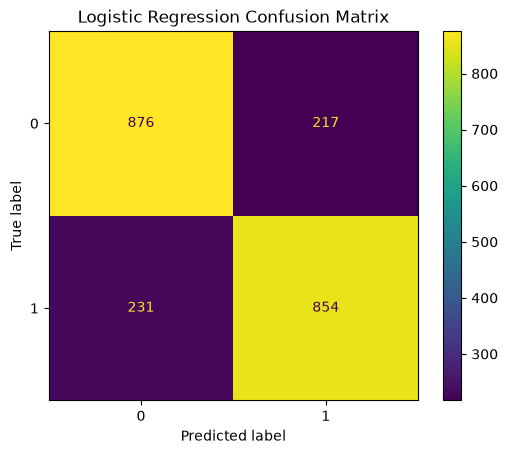

In [ ]:
# Evaluate Logistic Regression

accuracy_logistic = accuracy_score(y_test_class, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy_logistic)

ConfusionMatrixDisplay.from_predictions(
    y_test_class,
    y_pred_logistic
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

### 5.3 Decision Tree

In [ ]:
# Train a Decision Tree Regressor

tree_model = DecisionTreeRegressor(random_state=42)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
# Evaluate Decision Tree

mae_tree = mean_absolute_error(y_test, y_pred_tree)
mse_tree = mean_squared_error(y_test, y_pred_tree)
r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Results")
print("MAE:", mae_tree)
print("MSE:", mse_tree)
print("R²:", r2_tree)

Decision Tree Results
MAE: 36.72910927456382
MSE: 3587.2718089990817
R²: 0.8913176362790164


Observation: The Decision Tree performed substantially better than Linear Regression, achieving an R² score of 0.8913 and a lower MAE of 36.73. This suggests that the tree was able to capture non-linear patterns in bike rental demand more effectively.

Conclusion: Decision Tree performed much better than Linear Regression on the test set. It was able to capture non-linear relationships in the bike rental data effectively.

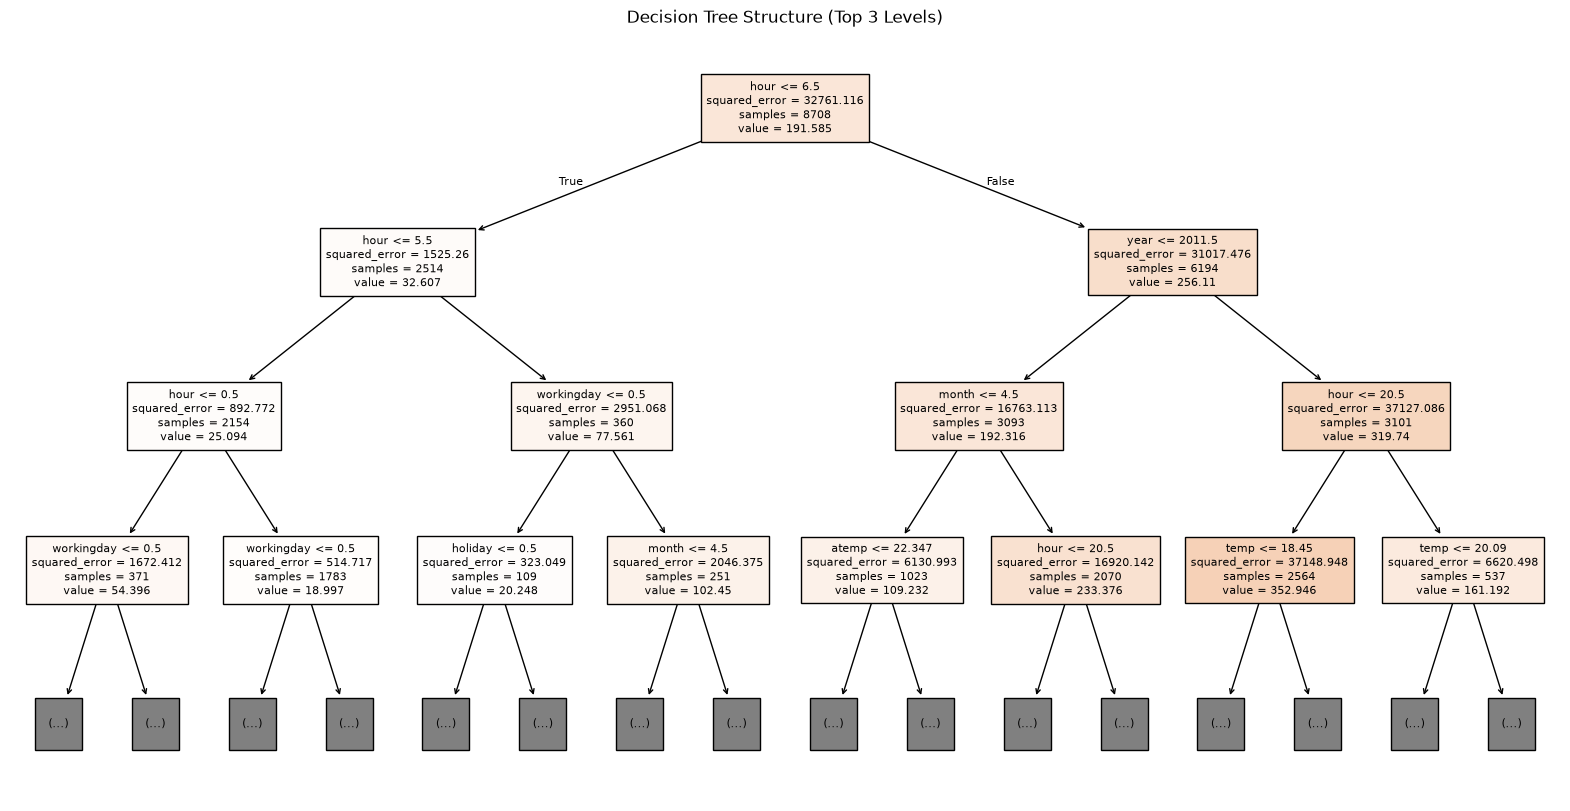

In [ ]:
# Visualize the Decision Tree

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model,
    feature_names=X.columns,
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Structure (Top 3 Levels)")
plt.show()

Observation: The top levels of the Decision Tree show that hour is the first and most important splitting feature, indicating that the time of day strongly influences bike rental demand. The tree then further divides the data using features such as year, working day, month, and temperature.

### 5.4 Random Forest Regressor

In [ ]:
# Train a Random Forest Regressor

forest_model = RandomForestRegressor(
    random_state=42
)

forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [ ]:
# Evaluate Random Forest

mae_forest = mean_absolute_error(y_test, y_pred_forest)
mse_forest = mean_squared_error(y_test, y_pred_forest)
r2_forest = r2_score(y_test, y_pred_forest)

print("Random Forest Results")
print("MAE:", mae_forest)
print("MSE:", mse_forest)
print("R²:", r2_forest)

Random Forest Results
MAE: 27.043700642791553
MSE: 1806.309077869605
R²: 0.9452748632815994


In [ ]:
y_train_pred_forest = forest_model.predict(X_train)

print("Training R²:", r2_score(y_train, y_train_pred_forest))
print("Testing R²:", r2_score(y_test, y_pred_forest))

Training R²: 0.9918678770759586
Testing R²: 0.9452748632815994


In [ ]:
feature_importance = pd.Series(
    forest_model.feature_importances_,
    index=X.columns
)

feature_importance = feature_importance.sort_values(ascending=False)

print("Top 3 Important Features:")
print(feature_importance.head(3))

Top 3 Important Features:
hour          0.602001
year          0.086252
workingday    0.079995
dtype: float64


Observation: Hour is the most important feature in the Random Forest, with an importance of 0.602. Year and workingday are the next two most important features. This suggests that the time of day has a strong influence on bike rental demand.

Conclusion: Random Forest gave strong prediction performance on the test set and performed better than the other regression models tested. The high importance of hour also shows that time of day is an important factor in predicting bike rental demand.

### 5.5 K-Nearest Neighbour (KNN)

In [ ]:
# Train KNN with K = 5

knn_model = KNeighborsRegressor(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)

print("KNN model trained successfully!")

KNN model trained successfully!


In [ ]:
# Evaluate KNN with K = 5

mae_knn = mean_absolute_error(y_test, y_pred_knn)
mse_knn = mean_squared_error(y_test, y_pred_knn)
r2_knn = r2_score(y_test, y_pred_knn)

print("KNN (K=5) Results")
print("MAE:", mae_knn)
print("MSE:", mse_knn)
print("R²:", r2_knn)

KNN (K=5) Results
MAE: 78.13590449954086
MSE: 13445.811533516988
R²: 0.5926367843262963


In [ ]:
# Train KNN with K = 3

knn_model_3 = KNeighborsRegressor(n_neighbors=3)

knn_model_3.fit(X_train_scaled, y_train)

y_pred_knn_3 = knn_model_3.predict(X_test_scaled)

# Evaluate KNN with K = 3

mae_knn_3 = mean_absolute_error(y_test, y_pred_knn_3)
mse_knn_3 = mean_squared_error(y_test, y_pred_knn_3)
r2_knn_3 = r2_score(y_test, y_pred_knn_3)

print("KNN (K=3) Results")
print("MAE:", mae_knn_3)
print("MSE:", mse_knn_3)
print("R²:", r2_knn_3)

KNN (K=3) Results
MAE: 74.58310376492194
MSE: 13165.935006631977
R²: 0.6011161090363939


In [ ]:
# Train KNN with K = 10

knn_model_10 = KNeighborsRegressor(n_neighbors=10)

knn_model_10.fit(X_train_scaled, y_train)

y_pred_knn_10 = knn_model_10.predict(X_test_scaled)

# Evaluate KNN with K = 10

mae_knn_10 = mean_absolute_error(y_test, y_pred_knn_10)
mse_knn_10 = mean_squared_error(y_test, y_pred_knn_10)
r2_knn_10 = r2_score(y_test, y_pred_knn_10)

print("KNN (K=10) Results")
print("MAE:", mae_knn_10)
print("MSE:", mse_knn_10)
print("R²:", r2_knn_10)

KNN (K=10) Results
MAE: 83.55583103764923
MSE: 14080.023076216712
R²: 0.5734222911878548


Observation: K=3 performed best among the tested K values, with the lowest MAE and MSE and the highest R². As K increased from 3 to 10, the model's performance decreased on the test set.

Conclusion: KNN performed best with K=3 among the tested values. Increasing K to 5 and 10 reduced performance on the test set.

In [ ]:
# Compare all five models

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN (K=3)"
    ],
    "Metric": [
        "R²",
        "Accuracy",
        "R²",
        "R²",
        "R²"
    ],
    "Score": [
        r2_linear,
        accuracy_logistic,
        r2_tree,
        r2_forest,
        r2_knn_3
    ]
})

comparison

,Model,Metric,Score
0,Linear Regression,R²,0.400602
1,Logistic Regression,Accuracy,0.794307
2,Decision Tree,R²,0.891318
3,Random Forest,R²,0.945275
4,KNN (K=3),R²,0.601116


## Model Comparison and Final Choice

Among the regression models, Random Forest achieved the best performance with an R² score of 0.9453, while Linear Regression had the lowest R² score of 0.4006. KNN with K=3 performed better than Linear Regression but worse than the tree-based models. Logistic Regression was evaluated separately as a classification model and achieved an accuracy of 79.43%.

Final Choice: Random Forest was selected as the best model for predicting bike rental count because it achieved the highest R² and lowest error among the regression models tested.